# Final Grouped-Target Test Evaluation

This notebook performs the one final evaluation of the complete three-class
business system on the ten held-out subjects.

The following components were frozen using only the 41 development subjects:

- the 18-to-3 activity mapping;
- the deterministic 222-feature representation;
- the direct three-class histogram-gradient-boosting model;
- food-confidence threshold 0.75;
- four consecutive food windows, corresponding to 20 seconds;
- five seconds of movement evidence for every final physical-activity window.

No classifier, threshold, temporal rule, or physical-accounting rule may be
changed after test results are observed.

The ten subjects were not used to develop or evaluate this grouped-target
system. The same subjects were previously evaluated in the separate 18-class
project, so they are not globally unseen within the repository.

## 1. Frozen-contract verification

This subsection verifies the complete development contract without loading test
sequences, test metadata, test features, or test predictions.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd


CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        candidate
        for candidate in [
            CURRENT_DIR,
            *CURRENT_DIR.parents,
        ]
        if (
            candidate
            / "business_case"
            / "artifacts"
            / "business_policy.json"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the activity_project root."
    )

MODELING_DIR = (
    PROJECT_ROOT
    / "modeling"
)

if str(MODELING_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(MODELING_DIR),
    )

from engineered_features import (
    extract_engineered_features,
)


BUSINESS_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "business_case"
    / "artifacts"
)

MODEL_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "modeling"
    / "artifacts"
)

SEQUENCE_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "modified"
    / "watch_pair_20hz"
)

POLICY_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "business_policy.json"
)

GROUPED_RESULT_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "grouped_target_result.json"
)

MAPPING_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "activity_group_mapping.json"
)

OOF_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "direct_oof_predictions.parquet"
)

FEATURE_META_PATH = (
    MODEL_ARTIFACT_DIR
    / "engineered_222_meta.json"
)

TRAIN_FEATURE_PATH = (
    MODEL_ARTIFACT_DIR
    / "engineered_222_train.parquet"
)

TRAIN_METADATA_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "train_metadata.parquet"
)

PREPROCESSING_META_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "preprocessing_meta.json"
)


def file_sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for chunk in iter(
            lambda: file.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


EXPECTED_POLICY_SHA256 = (
    "55b66d56a65484e73e2f80c7ac3413c"
    "55aacfcd169622eb9a8341bffccbe19ea"
)

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/yairlutaty/dev/yair.lutaty/projects/activity_project


In [2]:
policy_record = json.loads(
    POLICY_PATH.read_text(
        encoding="utf-8"
    )
)

grouped_result = json.loads(
    GROUPED_RESULT_PATH.read_text(
        encoding="utf-8"
    )
)

mapping_record = json.loads(
    MAPPING_PATH.read_text(
        encoding="utf-8"
    )
)

feature_meta = json.loads(
    FEATURE_META_PATH.read_text(
        encoding="utf-8"
    )
)

preprocessing_meta = json.loads(
    PREPROCESSING_META_PATH.read_text(
        encoding="utf-8"
    )
)

assert file_sha256(
    POLICY_PATH
) == EXPECTED_POLICY_SHA256

assert policy_record[
    "schema_version"
] == 2

assert policy_record[
    "status"
] == (
    "frozen_before_grouped_target_test"
)

assert grouped_result[
    "status"
] == (
    "development_selected_"
    "without_unbiased_final_test"
)

assert grouped_result[
    "selection"
][
    "selected_approach"
] == "direct_3_class"

assert policy_record[
    "classifier"
][
    "selected_approach"
] == "direct_3_class"

assert policy_record[
    "classifier"
][
    "estimator"
] == grouped_result[
    "estimator"
]

assert policy_record[
    "classifier"
][
    "input_features"
] == len(
    feature_meta[
        "feature_names"
    ]
) == 222

assert policy_record[
    "classifier"
][
    "business_labels"
] == mapping_record[
    "business_labels"
]

for artifact_name, artifact_path in [
    (
        "grouped_target_result",
        GROUPED_RESULT_PATH,
    ),
    (
        "activity_group_mapping",
        MAPPING_PATH,
    ),
    (
        "development_oof_predictions",
        OOF_PATH,
    ),
]:
    assert file_sha256(
        artifact_path
    ) == policy_record[
        "source_artifacts"
    ][
        artifact_name
    ][
        "sha256"
    ]

assert policy_record[
    "window_policy"
][
    "food_probability_threshold"
] == 0.75

assert policy_record[
    "temporal_policy"
][
    "required_consecutive_food_windows"
] == 4

assert policy_record[
    "temporal_policy"
][
    "confirmation_seconds"
] == 20

assert policy_record[
    "physical_activity_policy"
][
    "seconds_per_predicted_physical_window"
] == 5

assert policy_record[
    "physical_activity_policy"
][
    "additional_probability_threshold"
] is None

assert policy_record[
    "physical_activity_policy"
][
    "consecutive_windows_required"
] is False

BUSINESS_LABELS = policy_record[
    "classifier"
][
    "business_labels"
]

BUSINESS_GROUP_BY_ACTIVITY = (
    mapping_record[
        "activity_code_to_business_label"
    ]
)

FEATURE_NAMES = feature_meta[
    "feature_names"
]

TARGET_RATE_HZ = float(
    preprocessing_meta[
        "resampling"
    ][
        "target_rate_hz"
    ]
)

print(
    "Policy schema:",
    policy_record["schema_version"],
)

print(
    "Policy SHA-256 verified:",
    file_sha256(POLICY_PATH),
)

print(
    "Business labels:",
    BUSINESS_LABELS,
)

print(
    "Feature count:",
    len(FEATURE_NAMES),
)

print(
    "Food policy:",
    (
        "probability >= 0.75 and "
        "4 consecutive windows"
    ),
)

print(
    "Physical policy:",
    "5 seconds per final physical window",
)

print(
    "No test artifact has been loaded."
)

Policy schema: 2
Policy SHA-256 verified: 55b66d56a65484e73e2f80c7ac3413c55aacfcd169622eb9a8341bffccbe19ea
Business labels: ['physical_activity', 'food_or_drink', 'other_daily_activity']
Feature count: 222
Food policy: probability >= 0.75 and 4 consecutive windows
Physical policy: 5 seconds per final physical window
No test artifact has been loaded.


### Contract-verification finding

The schema-version-2 policy and every referenced development artifact match
their frozen SHA-256 checksums. The classifier, feature representation,
three-class mapping, food-event rule, and physical-accounting rule are therefore
confirmed before test access.

## 2. Final development fit

The established 222-feature development table is aligned with its authoritative
metadata and mapped to the frozen three-class target. The frozen histogram-
gradient-boosting model is then fitted on all 25,585 examples from the 41
development subjects.

This is a final fit, not another model-selection experiment. No training score,
threshold adjustment, or alternative model is considered. Test artifacts remain
unopened during this subsection.

In [3]:
train_feature_table = pd.read_parquet(
    TRAIN_FEATURE_PATH
)

train_metadata = pd.read_parquet(
    TRAIN_METADATA_PATH
)

assert train_feature_table.columns.tolist() == [
    "array_index",
    *FEATURE_NAMES,
]

assert np.array_equal(
    train_feature_table[
        "array_index"
    ].to_numpy(),
    train_metadata[
        "array_index"
    ].to_numpy(),
)

X_development = (
    train_feature_table[
        FEATURE_NAMES
    ].to_numpy()
)

y_activity_development = (
    train_metadata[
        "activity_code"
    ]
    .astype(str)
    .to_numpy()
)

y_development = (
    pd.Series(
        y_activity_development
    )
    .map(
        BUSINESS_GROUP_BY_ACTIVITY
    )
    .to_numpy()
)

development_subjects = set(
    train_metadata[
        "user_id"
    ]
    .astype(int)
    .unique()
)

expected_development_subjects = set(
    preprocessing_meta[
        "subjects"
    ][
        "train"
    ]
)

assert X_development.shape == (
    25_585,
    222,
)

assert np.isfinite(
    X_development
).all()

assert not pd.isna(
    y_development
).any()

assert set(
    y_activity_development
) == set(
    BUSINESS_GROUP_BY_ACTIVITY
)

assert set(
    y_development
) == set(
    BUSINESS_LABELS
)

assert development_subjects == (
    expected_development_subjects
)

assert len(
    development_subjects
) == 41

development_support = (
    pd.DataFrame({
        "business_label": (
            y_development
        ),
        "user_id": (
            train_metadata[
                "user_id"
            ].to_numpy()
        ),
    })
    .groupby(
        "business_label",
        observed=True,
    )
    .agg(
        examples=(
            "business_label",
            "size",
        ),
        subjects=(
            "user_id",
            "nunique",
        ),
    )
    .reindex(
        BUSINESS_LABELS
    )
)

print(
    "Development feature shape:",
    X_development.shape,
)

print(
    "Development subjects:",
    len(development_subjects),
)

print(
    "Feature and metadata alignment:",
    True,
)

print(
    "No test artifact has been loaded."
)

development_support

Development feature shape: (25585, 222)
Development subjects: 41
Feature and metadata alignment: True
No test artifact has been loaded.


,examples,subjects
business_label,,
physical_activity,8470,41
food_or_drink,7105,41
other_daily_activity,10010,41


In [4]:
from time import perf_counter

from sklearn.ensemble import (
    HistGradientBoostingClassifier,
)


ESTIMATOR_PARAMETERS = (
    policy_record[
        "classifier"
    ][
        "estimator"
    ][
        "parameters"
    ]
    .copy()
)

final_grouped_model = (
    HistGradientBoostingClassifier(
        **ESTIMATOR_PARAMETERS
    )
)

fit_start = perf_counter()

final_grouped_model.fit(
    X_development,
    y_development,
)

fit_seconds = (
    perf_counter()
    - fit_start
)

assert set(
    final_grouped_model.classes_
) == set(
    BUSINESS_LABELS
)

print(
    "Final grouped model fitted."
)

print(
    "Training examples:",
    f"{len(y_development):,}",
)

print(
    "Training subjects:",
    len(development_subjects),
)

print(
    "Model classes:",
    final_grouped_model.classes_.tolist(),
)

print(
    "Fit time:",
    f"{fit_seconds:.1f}s",
)

print(
    "No test artifact has been loaded "
    "and no test prediction exists."
)

Final grouped model fitted.
Training examples: 25,585
Training subjects: 41
Model classes: ['food_or_drink', 'other_daily_activity', 'physical_activity']
Fit time: 10.7s
No test artifact has been loaded and no test prediction exists.


### Final-fit finding

The frozen direct three-class model was fitted successfully on all 25,585
development examples from 41 subjects. Its class set matches the frozen target,
and no test artifact has yet been loaded.

## 3. One-time test access and window-level evaluation

**Test access begins in this subsection.**

The test sequences and metadata are loaded once, transformed with the same
deterministic 222-feature extractor, and evaluated using the already-fitted
model.

Two window-level outputs are reported:

1. **Raw classifier:** ordinary three-class probability argmax;
2. **Final window policy:** apply the frozen 0.75 food-confidence gate and
   reassign rejected food predictions to the higher-probability non-food class.

Both outputs come from the same single probability matrix. No alternative
model, threshold, or fallback rule is considered after the results are shown.

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)


def group_metric_table(
    y_true,
    y_pred,
):
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=BUSINESS_LABELS,
            zero_division=0,
        )
    )

    return pd.DataFrame({
        "business_label": BUSINESS_LABELS,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support.astype(int),
    }).set_index(
        "business_label"
    )


def calculate_window_metrics(
    y_true,
    y_pred,
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    group_metrics = group_metric_table(
        y_true,
        y_pred,
    )

    true_food = (
        y_true == "food_or_drink"
    )

    predicted_food = (
        y_pred == "food_or_drink"
    )

    true_physical = (
        y_true == "physical_activity"
    )

    predicted_physical = (
        y_pred == "physical_activity"
    )

    food_false_positive_rate = (
        (
            ~true_food
            & predicted_food
        ).sum()
        / (
            ~true_food
        ).sum()
    )

    physical_false_positive_rate = (
        (
            ~true_physical
            & predicted_physical
        ).sum()
        / (
            ~true_physical
        ).sum()
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": (
            group_metrics[
                "recall"
            ].mean()
        ),
        "macro_f1": (
            group_metrics[
                "f1"
            ].mean()
        ),
        "food_precision": group_metrics.loc[
            "food_or_drink",
            "precision",
        ],
        "food_recall": group_metrics.loc[
            "food_or_drink",
            "recall",
        ],
        "food_f1": group_metrics.loc[
            "food_or_drink",
            "f1",
        ],
        "food_false_positive_rate": (
            food_false_positive_rate
        ),
        "physical_precision": group_metrics.loc[
            "physical_activity",
            "precision",
        ],
        "physical_recall": group_metrics.loc[
            "physical_activity",
            "recall",
        ],
        "physical_f1": group_metrics.loc[
            "physical_activity",
            "f1",
        ],
        "physical_false_positive_rate": (
            physical_false_positive_rate
        ),
    }


def apply_frozen_food_gate(
    probabilities,
):
    probabilities = np.asarray(
        probabilities
    )

    label_array = np.asarray(
        BUSINESS_LABELS
    )

    predictions = label_array[
        probabilities.argmax(axis=1)
    ].copy()

    food_index = BUSINESS_LABELS.index(
        "food_or_drink"
    )

    food_threshold = policy_record[
        "window_policy"
    ][
        "food_probability_threshold"
    ]

    rejected_food = (
        (
            predictions
            == "food_or_drink"
        )
        & (
            probabilities[
                :,
                food_index,
            ]
            < food_threshold
        )
    )

    non_food_labels = np.asarray([
        "physical_activity",
        "other_daily_activity",
    ])

    non_food_indices = [
        BUSINESS_LABELS.index(
            label
        )
        for label in non_food_labels
    ]

    fallback_predictions = (
        non_food_labels[
            probabilities[
                :,
                non_food_indices,
            ].argmax(axis=1)
        ]
    )

    predictions[
        rejected_food
    ] = fallback_predictions[
        rejected_food
    ]

    return predictions

In [6]:
TEST_SEQUENCE_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "test_sequences.npz"
)

TEST_METADATA_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "test_metadata.parquet"
)

test_metadata = pd.read_parquet(
    TEST_METADATA_PATH
)

feature_start = perf_counter()

with np.load(
    TEST_SEQUENCE_PATH
) as artifact:
    X_test, test_feature_names = (
        extract_engineered_features(
            artifact["accel"],
            artifact["gyro"],
            TARGET_RATE_HZ,
        )
    )

feature_seconds = (
    perf_counter()
    - feature_start
)

assert test_feature_names == (
    FEATURE_NAMES
)

assert np.array_equal(
    test_metadata[
        "array_index"
    ].to_numpy(),
    np.arange(
        len(test_metadata)
    ),
)

expected_test_subjects = set(
    preprocessing_meta[
        "subjects"
    ][
        "test"
    ]
)

observed_test_subjects = set(
    test_metadata[
        "user_id"
    ]
    .astype(int)
    .unique()
)

assert observed_test_subjects == (
    expected_test_subjects
)

assert development_subjects.isdisjoint(
    observed_test_subjects
)

assert X_test.shape == (
    6_161,
    222,
)

assert np.isfinite(
    X_test
).all()

y_activity_test = (
    test_metadata[
        "activity_code"
    ]
    .astype(str)
    .to_numpy()
)

y_test = (
    pd.Series(
        y_activity_test
    )
    .map(
        BUSINESS_GROUP_BY_ACTIVITY
    )
    .to_numpy()
)

assert not pd.isna(
    y_test
).any()

assert set(
    y_activity_test
).issubset(
    set(
        BUSINESS_GROUP_BY_ACTIVITY
    )
)

assert set(
    y_test
) == set(
    BUSINESS_LABELS
)

prediction_start = perf_counter()

model_test_probabilities = (
    final_grouped_model.predict_proba(
        X_test
    )
)

prediction_seconds = (
    perf_counter()
    - prediction_start
)

class_index_by_label = {
    str(label): index
    for index, label in enumerate(
        final_grouped_model.classes_
    )
}

test_probabilities = (
    model_test_probabilities[
        :,
        [
            class_index_by_label[
                label
            ]
            for label in BUSINESS_LABELS
        ],
    ]
)

assert np.allclose(
    test_probabilities.sum(axis=1),
    1.0,
)

raw_test_prediction = (
    np.asarray(
        BUSINESS_LABELS
    )[
        test_probabilities.argmax(
            axis=1
        )
    ]
)

policy_test_prediction = (
    apply_frozen_food_gate(
        test_probabilities
    )
)

test_predictions = (
    test_metadata[
        [
            "array_index",
            "pair_id",
            "user_id",
            "activity_code",
            "window_position",
        ]
    ]
    .copy()
)

test_predictions[
    "y_true"
] = y_test

test_predictions[
    "y_pred_raw"
] = raw_test_prediction

test_predictions[
    "y_pred_policy"
] = policy_test_prediction

for label_index, label in enumerate(
    BUSINESS_LABELS
):
    test_predictions[
        f"prob_{label}"
    ] = test_probabilities[
        :,
        label_index,
    ]

assert len(
    test_predictions
) == 6_161

assert test_predictions[
    "array_index"
].is_unique

raw_test_metrics = (
    calculate_window_metrics(
        y_test,
        raw_test_prediction,
    )
)

policy_window_test_metrics = (
    calculate_window_metrics(
        y_test,
        policy_test_prediction,
    )
)

window_test_comparison = pd.DataFrame([
    {
        "output": "raw_classifier",
        **raw_test_metrics,
    },
    {
        "output": "final_window_policy",
        **policy_window_test_metrics,
    },
])

policy_group_test_metrics = (
    group_metric_table(
        y_test,
        policy_test_prediction,
    )
)

print(
    "FINAL GROUPED-TARGET TEST ACCESSED"
)

print(
    "Test examples:",
    f"{len(test_predictions):,}",
)

print(
    "Test subjects:",
    len(observed_test_subjects),
)

print(
    "Feature extraction time:",
    f"{feature_seconds:.1f}s",
)

print(
    "Prediction time:",
    f"{prediction_seconds:.2f}s",
)

display(
    window_test_comparison.round(4)
)

display(
    policy_group_test_metrics.round(4)
)

FINAL GROUPED-TARGET TEST ACCESSED
Test examples: 6,161
Test subjects: 10
Feature extraction time: 0.5s
Prediction time: 0.16s


,output,accuracy,balanced_accuracy,macro_f1,food_precision,food_recall,food_f1,food_false_positive_rate,physical_precision,physical_recall,physical_f1,physical_false_positive_rate
0,raw_classifier,0.8713,0.8643,0.8708,0.8671,0.7761,0.8191,0.0459,0.9810,0.9129,0.9457,0.0087
1,final_window_policy,0.8630,0.8508,0.8603,0.8981,0.7090,0.7924,0.0310,0.9799,0.9133,0.9455,0.0092


,precision,recall,f1,support
business_label,,,,
physical_activity,0.9799,0.9133,0.9455,2031
food_or_drink,0.8981,0.7090,0.7924,1715
other_daily_activity,0.7708,0.9300,0.8429,2415


### Window-level test findings

The raw grouped classifier reaches test macro-F1 0.8708, below its development
mean of 0.9158. This indicates a real subject-generalization decrease.

The frozen food-confidence gate behaves as designed: it raises food-or-drink
precision from 0.8671 to 0.8981 and reduces the non-food false-positive rate
from 0.0459 to 0.0310. The cost is a reduction in food recall from 0.7761 to
0.7090 and in food F1 from 0.8191 to 0.7924.

Physical activity remains the strongest test class after the policy, with
precision 0.9799, recall 0.9133, and F1 0.9455. Other daily activity reaches
recall 0.9300 but precision 0.7708, showing that it absorbs many missed windows
from the two target-action classes.

These results do not trigger any adjustment. The classifier and policy remain
frozen.


## 4. Frozen event and movement policies on test data

The 20-second food-event rule is now applied exactly as frozen. Candidate food
runs are constructed only within each subject/activity recording, and gaps in
canonical window position reset the run.

Physical movement evidence is calculated independently by assigning five
seconds to every final physical-activity window.

These remain controlled recording-level diagnostics, not estimates of natural
daily events, notifications, exercise sessions, or calories.

In [7]:
def build_food_run_tables(
    data,
    prediction_column,
):
    sequence_data = data[
        [
            "user_id",
            "activity_code",
            "window_position",
            "y_true",
            prediction_column,
        ]
    ].copy()

    sequence_data[
        "candidate_food"
    ] = (
        sequence_data[
            prediction_column
        ]
        == "food_or_drink"
    )

    sequence_data = (
        sequence_data
        .sort_values(
            [
                "user_id",
                "activity_code",
                "window_position",
            ]
        )
        .reset_index(drop=True)
    )

    recording_rows = []
    run_rows = []

    for (
        user_id,
        activity_code,
    ), recording in (
        sequence_data.groupby(
            [
                "user_id",
                "activity_code",
            ],
            sort=True,
        )
    ):
        true_labels = (
            recording[
                "y_true"
            ].unique()
        )

        assert len(true_labels) == 1

        positions = recording[
            "window_position"
        ].to_numpy()

        positive = recording[
            "candidate_food"
        ].to_numpy()

        continuation = np.zeros(
            len(recording),
            dtype=bool,
        )

        if len(recording) > 1:
            continuation[1:] = (
                positive[1:]
                & positive[:-1]
                & (
                    np.diff(positions)
                    == 1
                )
            )

        run_starts = (
            positive
            & ~continuation
        )

        run_ids = np.cumsum(
            run_starts
        )

        if positive.any():
            run_lengths = (
                pd.Series(
                    run_ids[positive]
                )
                .value_counts(
                    sort=False
                )
                .sort_index()
            )
        else:
            run_lengths = (
                pd.Series(dtype=int)
            )

        recording_rows.append({
            "user_id": int(user_id),
            "activity_code": str(
                activity_code
            ),
            "y_true": str(
                true_labels[0]
            ),
            "windows": int(
                len(recording)
            ),
            "maximum_food_run": (
                int(
                    run_lengths.max()
                )
                if len(run_lengths)
                else 0
            ),
        })

        for run_number, run_length in (
            enumerate(
                run_lengths,
                start=1,
            )
        ):
            run_rows.append({
                "user_id": int(user_id),
                "activity_code": str(
                    activity_code
                ),
                "y_true": str(
                    true_labels[0]
                ),
                "run_number": int(
                    run_number
                ),
                "run_length": int(
                    run_length
                ),
            })

    recording_table = pd.DataFrame(
        recording_rows
    )

    run_table = pd.DataFrame(
        run_rows,
        columns=[
            "user_id",
            "activity_code",
            "y_true",
            "run_number",
            "run_length",
        ],
    )

    return (
        recording_table,
        run_table,
    )

In [8]:
REQUIRED_FOOD_WINDOWS = (
    policy_record[
        "temporal_policy"
    ][
        "required_consecutive_food_windows"
    ]
)

SECONDS_PER_PHYSICAL_WINDOW = (
    policy_record[
        "physical_activity_policy"
    ][
        "seconds_per_predicted_physical_window"
    ]
)

assert REQUIRED_FOOD_WINDOWS == 4
assert SECONDS_PER_PHYSICAL_WINDOW == 5

test_recordings, test_food_runs = (
    build_food_run_tables(
        test_predictions,
        "y_pred_policy",
    )
)

qualifying_test_food_runs = (
    test_food_runs[
        test_food_runs[
            "run_length"
        ] >= REQUIRED_FOOD_WINDOWS
    ]
)

test_event_counts = (
    qualifying_test_food_runs
    .groupby(
        [
            "user_id",
            "activity_code",
        ],
        observed=True,
    )
    .size()
    .rename(
        "qualifying_event_count"
    )
    .reset_index()
)

test_recordings = (
    test_recordings
    .merge(
        test_event_counts,
        on=[
            "user_id",
            "activity_code",
        ],
        how="left",
        validate="one_to_one",
    )
)

test_recordings[
    "qualifying_event_count"
] = (
    test_recordings[
        "qualifying_event_count"
    ]
    .fillna(0)
    .astype(int)
)

test_recordings[
    "event_detected"
] = (
    test_recordings[
        "qualifying_event_count"
    ] > 0
)

test_food_recordings = (
    test_recordings[
        test_recordings[
            "y_true"
        ] == "food_or_drink"
    ]
)

test_non_food_recordings = (
    test_recordings[
        test_recordings[
            "y_true"
        ] != "food_or_drink"
    ]
)

test_non_food_hours = (
    test_non_food_recordings[
        "windows"
    ].sum()
    * 5.0
    / 3600.0
)

test_recording_support = (
    test_recordings
    .groupby(
        "y_true",
        observed=True,
    )
    .agg(
        recordings=(
            "activity_code",
            "size",
        ),
        windows=(
            "windows",
            "sum",
        ),
        minimum_windows=(
            "windows",
            "min",
        ),
        median_windows=(
            "windows",
            "median",
        ),
        maximum_windows=(
            "windows",
            "max",
        ),
    )
    .reindex(
        BUSINESS_LABELS
    )
)

food_event_test_summary = pd.Series({
    "required_consecutive_windows": (
        REQUIRED_FOOD_WINDOWS
    ),
    "confirmation_seconds": (
        REQUIRED_FOOD_WINDOWS * 5
    ),
    "food_recordings": len(
        test_food_recordings
    ),
    "detected_food_recordings": int(
        test_food_recordings[
            "event_detected"
        ].sum()
    ),
    "food_recording_detection_rate": (
        test_food_recordings[
            "event_detected"
        ].mean()
    ),
    "non_food_recordings": len(
        test_non_food_recordings
    ),
    "alerted_non_food_recordings": int(
        test_non_food_recordings[
            "event_detected"
        ].sum()
    ),
    "non_food_recording_alert_rate": (
        test_non_food_recordings[
            "event_detected"
        ].mean()
    ),
    "true_qualifying_runs": int(
        qualifying_test_food_runs[
            "y_true"
        ]
        .eq("food_or_drink")
        .sum()
    ),
    "false_qualifying_runs": int(
        qualifying_test_food_runs[
            "y_true"
        ]
        .ne("food_or_drink")
        .sum()
    ),
    "controlled_false_runs_per_non_food_hour": (
        qualifying_test_food_runs[
            "y_true"
        ]
        .ne("food_or_drink")
        .sum()
        / test_non_food_hours
    ),
})

display(
    test_recording_support
)

display(
    food_event_test_summary
    .to_frame(
        name="test_value"
    )
    .round(4)
)

,recordings,windows,minimum_windows,median_windows,maximum_windows
y_true,,,,,
physical_activity,58,2031,35,35.0,36
food_or_drink,49,1715,35,35.0,35
other_daily_activity,69,2415,35,35.0,35


,test_value
required_consecutive_windows,4.0000
confirmation_seconds,20.0000
food_recordings,49.0000
detected_food_recordings,41.0000
food_recording_detection_rate,0.8367
non_food_recordings,127.0000
alerted_non_food_recordings,5.0000
non_food_recording_alert_rate,0.0394
true_qualifying_runs,84.0000
false_qualifying_runs,12.0000


In [9]:
true_physical_test_windows = (
    test_predictions[
        "y_true"
    ]
    .eq("physical_activity")
    .sum()
)

predicted_physical_test_windows = (
    test_predictions[
        "y_pred_policy"
    ]
    .eq("physical_activity")
    .sum()
)

actual_physical_test_seconds = int(
    true_physical_test_windows
    * SECONDS_PER_PHYSICAL_WINDOW
)

predicted_physical_test_seconds = int(
    predicted_physical_test_windows
    * SECONDS_PER_PHYSICAL_WINDOW
)

physical_accounting_test_summary = (
    pd.Series({
        "physical_precision": (
            policy_window_test_metrics[
                "physical_precision"
            ]
        ),
        "physical_recall": (
            policy_window_test_metrics[
                "physical_recall"
            ]
        ),
        "physical_f1": (
            policy_window_test_metrics[
                "physical_f1"
            ]
        ),
        "physical_false_positive_rate": (
            policy_window_test_metrics[
                "physical_false_positive_rate"
            ]
        ),
        "actual_physical_minutes": (
            actual_physical_test_seconds
            / 60.0
        ),
        "predicted_physical_minutes": (
            predicted_physical_test_seconds
            / 60.0
        ),
        "duration_error_minutes": (
            (
                predicted_physical_test_seconds
                - actual_physical_test_seconds
            )
            / 60.0
        ),
        "relative_duration_error": (
            (
                predicted_physical_test_seconds
                - actual_physical_test_seconds
            )
            / actual_physical_test_seconds
        ),
    })
)

display(
    physical_accounting_test_summary
    .to_frame(
        name="test_value"
    )
    .round(4)
)

,test_value
physical_precision,0.9799
physical_recall,0.9133
physical_f1,0.9455
physical_false_positive_rate,0.0092
actual_physical_minutes,169.2500
predicted_physical_minutes,157.7500
duration_error_minutes,-11.5000
relative_duration_error,-0.0679


### Frozen-policy test findings

The frozen food-event policy detects 41 of 49 controlled food recordings, for a
test detection rate of 0.8367 compared with 0.9015 in development.

Five of 127 non-food recordings produce at least one candidate food event,
giving an alert rate of 0.0394 compared with 0.0246 in development. The
controlled false-run rate rises from 0.6234 to 1.9433 per non-food hour. The
event policy therefore suppresses most non-food recordings but generalizes less
strongly than its development result suggested.

Physical movement evidence remains precise but is undercounted. The policy
records 157.75 minutes against 169.25 controlled physical minutes, an
underestimate of 11.5 minutes or 6.79%. Physical precision remains 0.9799, while
recall falls to 0.9133.

These values remain diagnostics from single-activity blocks. They do not
estimate false notifications per real-world hour or validated daily active
minutes.

## 5. Activity and subject robustness

The final diagnostics identify which original activities and held-out subjects
drive the test errors. They describe the frozen system and do not reopen model
or policy selection.

predicted_label,physical_activity,food_or_drink,other_daily_activity
true_label,,,
physical_activity,1855,3,173
food_or_drink,4,1216,495
other_daily_activity,34,135,2246


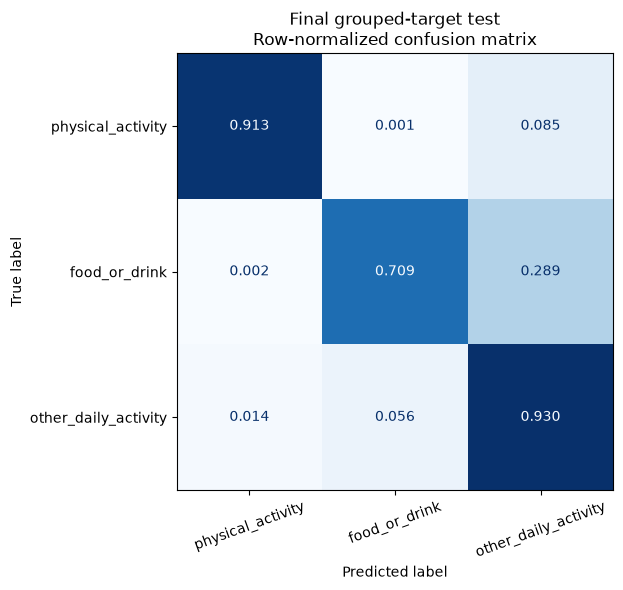

In [10]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
)


test_confusion_counts = confusion_matrix(
    test_predictions["y_true"],
    test_predictions[
        "y_pred_policy"
    ],
    labels=BUSINESS_LABELS,
)

test_confusion_normalized = np.divide(
    test_confusion_counts,
    test_confusion_counts.sum(
        axis=1,
        keepdims=True,
    ),
    out=np.zeros_like(
        test_confusion_counts,
        dtype=float,
    ),
    where=(
        test_confusion_counts.sum(
            axis=1,
            keepdims=True,
        )
        > 0
    ),
)

display(
    pd.DataFrame(
        test_confusion_counts,
        index=pd.Index(
            BUSINESS_LABELS,
            name="true_label",
        ),
        columns=pd.Index(
            BUSINESS_LABELS,
            name="predicted_label",
        ),
    )
)

figure, axis = plt.subplots(
    figsize=(8, 6)
)

ConfusionMatrixDisplay(
    confusion_matrix=(
        test_confusion_normalized
    ),
    display_labels=BUSINESS_LABELS,
).plot(
    ax=axis,
    cmap="Blues",
    values_format=".3f",
    colorbar=False,
)

axis.set_title(
    "Final grouped-target test\n"
    "Row-normalized confusion matrix"
)

axis.tick_params(
    axis="x",
    rotation=20,
)

plt.tight_layout()
plt.show()

In [11]:
ACTIVITY_NAME_BY_CODE = (
    mapping_record[
        "activity_code_to_name"
    ]
)

test_activity_event_metrics = (
    test_recordings
    .groupby(
        [
            "activity_code",
            "y_true",
        ],
        observed=True,
    )
    .agg(
        recordings=(
            "user_id",
            "size",
        ),
        recording_detection_or_alert_rate=(
            "event_detected",
            "mean",
        ),
        qualifying_runs=(
            "qualifying_event_count",
            "sum",
        ),
    )
    .reset_index()
)

test_activity_event_metrics.insert(
    1,
    "activity_name",
    test_activity_event_metrics[
        "activity_code"
    ].map(
        ACTIVITY_NAME_BY_CODE
    ),
)

test_physical_activity_metrics = (
    test_predictions.assign(
        predicted_physical=lambda frame: (
            frame["y_pred_policy"]
            == "physical_activity"
        )
    )
    .groupby(
        [
            "activity_code",
            "y_true",
        ],
        observed=True,
    )
    .agg(
        windows=(
            "array_index",
            "size",
        ),
        predicted_physical_windows=(
            "predicted_physical",
            "sum",
        ),
        predicted_physical_rate=(
            "predicted_physical",
            "mean",
        ),
    )
    .reset_index()
)

test_physical_activity_metrics.insert(
    1,
    "activity_name",
    test_physical_activity_metrics[
        "activity_code"
    ].map(
        ACTIVITY_NAME_BY_CODE
    ),
)

print(
    "Food-recording detection by activity"
)

display(
    test_activity_event_metrics[
        test_activity_event_metrics[
            "y_true"
        ] == "food_or_drink"
    ].round(4)
)

print(
    "Non-food activities producing "
    "candidate food events"
)

display(
    test_activity_event_metrics[
        (
            test_activity_event_metrics[
                "y_true"
            ] != "food_or_drink"
        )
        & (
            test_activity_event_metrics[
                "qualifying_runs"
            ] > 0
        )
    ]
    .sort_values(
        "qualifying_runs",
        ascending=False,
    )
    .round(4)
)

print(
    "Physical-activity window recall "
    "by original activity"
)

display(
    test_physical_activity_metrics[
        test_physical_activity_metrics[
            "y_true"
        ] == "physical_activity"
    ].round(4)
)

print(
    "Non-physical sources of movement evidence"
)

display(
    test_physical_activity_metrics[
        (
            test_physical_activity_metrics[
                "y_true"
            ] != "physical_activity"
        )
        & (
            test_physical_activity_metrics[
                "predicted_physical_windows"
            ] > 0
        )
    ]
    .sort_values(
        "predicted_physical_rate",
        ascending=False,
    )
    .round(4)
)

Food-recording detection by activity


,activity_code,activity_name,y_true,recordings,recording_detection_or_alert_rate,qualifying_runs
7,H,Eating Soup,food_or_drink,10,0.9000,13
8,I,Eating Chips,food_or_drink,10,0.8000,15
9,J,Eating Pasta,food_or_drink,10,0.9000,20
10,K,Drinking from Cup,food_or_drink,10,0.8000,20
11,L,Eating Sandwich,food_or_drink,9,0.7778,16


Non-food activities producing candidate food events


,activity_code,activity_name,y_true,recordings,recording_detection_or_alert_rate,qualifying_runs
16,R,Clapping,other_daily_activity,10,0.1000,4
3,D,Sitting,other_daily_activity,10,0.1000,3
15,Q,Writing,other_daily_activity,10,0.1000,3
4,E,Standing,other_daily_activity,9,0.1111,1
5,F,Typing,other_daily_activity,10,0.1000,1


Physical-activity window recall by original activity


,activity_code,activity_name,y_true,windows,predicted_physical_windows,predicted_physical_rate
0,A,Walking,physical_activity,350,347,0.9914
1,B,Jogging,physical_activity,350,349,0.9971
2,C,Stairs,physical_activity,315,297,0.9429
12,M,Kicking Soccer Ball,physical_activity,350,330,0.9429
13,O,Playing Catch,physical_activity,315,249,0.7905
14,P,Dribbling Basketball,physical_activity,351,283,0.8063


Non-physical sources of movement evidence


,activity_code,activity_name,y_true,windows,predicted_physical_windows,predicted_physical_rate
17,S,Folding Clothes,other_daily_activity,350,14,0.0400
16,R,Clapping,other_daily_activity,350,10,0.0286
4,E,Standing,other_daily_activity,315,7,0.0222
3,D,Sitting,other_daily_activity,350,2,0.0057
8,I,Eating Chips,food_or_drink,350,2,0.0057
11,L,Eating Sandwich,food_or_drink,315,1,0.0032
6,G,Brushing Teeth,other_daily_activity,350,1,0.0029
9,J,Eating Pasta,food_or_drink,350,1,0.0029


In [12]:
subject_test_rows = []

for user_id, subject_windows in (
    test_predictions.groupby(
        "user_id",
        sort=True,
    )
):
    subject_recordings = (
        test_recordings[
            test_recordings[
                "user_id"
            ] == user_id
        ]
    )

    subject_food_recordings = (
        subject_recordings[
            subject_recordings[
                "y_true"
            ] == "food_or_drink"
        ]
    )

    subject_non_food_recordings = (
        subject_recordings[
            subject_recordings[
                "y_true"
            ] != "food_or_drink"
        ]
    )

    subject_metrics = (
        calculate_window_metrics(
            subject_windows["y_true"],
            subject_windows[
                "y_pred_policy"
            ],
        )
    )

    actual_physical_seconds = int(
        subject_windows[
            "y_true"
        ]
        .eq("physical_activity")
        .sum()
        * SECONDS_PER_PHYSICAL_WINDOW
    )

    predicted_physical_seconds = int(
        subject_windows[
            "y_pred_policy"
        ]
        .eq("physical_activity")
        .sum()
        * SECONDS_PER_PHYSICAL_WINDOW
    )

    subject_test_rows.append({
        "user_id": int(user_id),
        "windows": len(
            subject_windows
        ),
        **subject_metrics,
        "food_recordings": len(
            subject_food_recordings
        ),
        "detected_food_recordings": int(
            subject_food_recordings[
                "event_detected"
            ].sum()
        ),
        "food_recording_detection_rate": (
            subject_food_recordings[
                "event_detected"
            ].mean()
        ),
        "non_food_recordings": len(
            subject_non_food_recordings
        ),
        "alerted_non_food_recordings": int(
            subject_non_food_recordings[
                "event_detected"
            ].sum()
        ),
        "non_food_recording_alert_rate": (
            subject_non_food_recordings[
                "event_detected"
            ].mean()
        ),
        "false_qualifying_runs": int(
            subject_non_food_recordings[
                "qualifying_event_count"
            ].sum()
        ),
        "actual_physical_seconds": (
            actual_physical_seconds
        ),
        "predicted_physical_seconds": (
            predicted_physical_seconds
        ),
        "physical_duration_error_seconds": (
            predicted_physical_seconds
            - actual_physical_seconds
        ),
        "physical_relative_duration_error": (
            (
                predicted_physical_seconds
                - actual_physical_seconds
            )
            / actual_physical_seconds
        ),
    })

subject_test_metrics = pd.DataFrame(
    subject_test_rows
)

display(
    subject_test_metrics[
        [
            "macro_f1",
            "food_precision",
            "food_recall",
            "food_recording_detection_rate",
            "non_food_recording_alert_rate",
            "physical_precision",
            "physical_recall",
            "physical_relative_duration_error",
        ]
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
    .T
    .round(4)
)

display(
    subject_test_metrics
    .sort_values(
        "macro_f1"
    )[
        [
            "user_id",
            "windows",
            "macro_f1",
            "food_precision",
            "food_recall",
            "food_recording_detection_rate",
            "alerted_non_food_recordings",
            "physical_precision",
            "physical_recall",
            "physical_duration_error_seconds",
            "physical_relative_duration_error",
        ]
    ]
    .round(4)
)

,count,mean,std,min,10%,25%,50%,75%,90%,max
macro_f1,10.0,0.8451,0.1762,0.4620,0.6551,0.7382,0.9292,0.9590,0.9708,0.9852
food_precision,10.0,0.8066,0.3280,0.0000,0.4734,0.7359,0.9760,0.9865,1.0000,1.0000
food_recall,10.0,0.7093,0.3167,0.0000,0.2623,0.7032,0.8457,0.9086,0.9291,0.9600
food_recording_detection_rate,10.0,0.8400,0.3502,0.0000,0.3600,1.0000,1.0000,1.0000,1.0000,1.0000
non_food_recording_alert_rate,10.0,0.0385,0.0831,0.0000,0.0000,0.0000,0.0000,0.0000,0.1615,0.2308
physical_precision,10.0,0.9821,0.0303,0.9182,0.9456,0.9654,1.0000,1.0000,1.0000,1.0000
physical_recall,10.0,0.9096,0.1405,0.6057,0.6949,0.9016,0.9786,0.9933,1.0000,1.0000
physical_relative_duration_error,10.0,-0.0723,0.1487,-0.3943,-0.3051,-0.0593,-0.0076,0.0000,0.0219,0.0476


,user_id,windows,macro_f1,food_precision,food_recall,food_recording_detection_rate,alerted_non_food_recordings,physical_precision,physical_recall,physical_duration_error_seconds,physical_relative_duration_error
6,1640,560,0.4620,0.0000,0.0000,0.0,0,1.0000,0.6057,-345,-0.3943
1,1607,631,0.6765,0.6623,0.2914,0.4,2,0.9538,0.8815,-80,-0.0758
5,1639,595,0.6837,0.5260,0.7214,1.0,3,1.0000,0.7048,-310,-0.2952
2,1618,595,0.9017,0.9760,0.6971,1.0,0,1.0000,0.9943,-5,-0.0057
9,1646,630,0.9094,1.0000,0.8114,1.0,0,0.9182,0.9619,50,0.0476
0,1606,630,0.9490,1.0000,0.9143,1.0,0,0.9486,0.9667,20,0.0190
4,1629,630,0.9537,0.9565,0.8800,1.0,0,1.0000,1.0000,0,0.0000
3,1626,630,0.9607,0.9811,0.8914,1.0,0,1.0000,0.9905,-10,-0.0095
7,1641,630,0.9691,0.9759,0.9257,1.0,0,1.0000,0.9905,-10,-0.0095
8,1643,630,0.9852,0.9882,0.9600,1.0,0,1.0000,1.0000,0,0.0000


### Activity and subject findings

Food-event detection varies moderately by intake activity. Eating Soup and
Eating Pasta each reach 0.90 recording detection, Eating Chips and Drinking from
Cup reach 0.80, and Eating Sandwich reaches 0.7778.

Candidate food events on non-food data arise from Clapping, Sitting, Writing,
Standing, and Typing. The 12 false qualifying runs are concentrated in only five
recordings and two subjects rather than being distributed uniformly.

Physical recognition remains almost perfect for Walking and Jogging. Playing
Catch reaches only 0.7905 window recall and Dribbling Basketball 0.8063,
accounting for much of the physical-duration underestimate. Folding Clothes is
again the largest non-physical source of movement evidence, although only 4% of
its test windows are labelled physical.

Wearer variability is the most important limitation. Median subject macro-F1 is
0.9292, but subject 1640 reaches only 0.4620, detects no food recording, and
undercounts physical duration by 39.4%. Subject 1607 reaches macro-F1 0.6765 and
detects two of five food recordings. Subject 1639 reaches macro-F1 0.6837 and
produces three alerted non-food recordings.

Subjects 1639 and 1640 were also difficult in the separate 18-class evaluation.
The grouped business target simplifies the class structure but does not resolve
their broader subject-specific distribution shift.

## 6. Final conclusions

The complete frozen three-class system has now been evaluated once on the ten
held-out subjects.

The raw grouped classifier reaches test macro-F1 0.8708. The final food gate
raises food precision to 0.8981 while reducing recall to 0.7090. The 20-second
event policy detects 83.67% of controlled food recordings and alerts 3.94% of
controlled non-food recordings.

Physical activity remains strong at precision 0.9799, recall 0.9133, and F1
0.9455. Its hard-window accounting rule underestimates controlled physical
duration by 6.79%.

The system demonstrates useful signal for both business actions, but it is not
ready for real-world notifications or validated activity accounting. The
controlled block design, artificial activity prevalence, lack of natural
transitions, undefined cooldown behavior, and severe failures for some wearers
remain material limitations.

No model, threshold, temporal rule, or accounting rule will be changed after
this test.

In [13]:
import joblib


FINAL_GROUPED_MODEL_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "grouped_final_model.joblib"
)

FINAL_TEST_PREDICTIONS_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "grouped_test_predictions.parquet"
)

FINAL_TEST_RECORDINGS_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "grouped_test_recordings.parquet"
)

FINAL_TEST_RESULT_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "grouped_test_result.json"
)

joblib.dump(
    final_grouped_model,
    FINAL_GROUPED_MODEL_PATH,
)

test_predictions.to_parquet(
    FINAL_TEST_PREDICTIONS_PATH,
    index=False,
    compression="zstd",
)

test_recordings.to_parquet(
    FINAL_TEST_RECORDINGS_PATH,
    index=False,
    compression="zstd",
)


def serialize_metric_dict(
    metrics,
):
    return {
        str(name): float(value)
        for name, value in (
            metrics.items()
        )
    }


group_test_result_record = {
    str(label): {
        "precision": float(
            row["precision"]
        ),
        "recall": float(
            row["recall"]
        ),
        "f1": float(
            row["f1"]
        ),
        "support": int(
            row["support"]
        ),
    }
    for label, row in (
        policy_group_test_metrics
        .iterrows()
    )
}

food_activity_test_record = {
    str(row.activity_code): {
        "activity_name": str(
            row.activity_name
        ),
        "business_label": str(
            row.y_true
        ),
        "recordings": int(
            row.recordings
        ),
        "recording_detection_or_alert_rate": float(
            row.recording_detection_or_alert_rate
        ),
        "qualifying_runs": int(
            row.qualifying_runs
        ),
    }
    for row in (
        test_activity_event_metrics
        .itertuples(index=False)
    )
}

physical_activity_test_record = {
    str(row.activity_code): {
        "activity_name": str(
            row.activity_name
        ),
        "business_label": str(
            row.y_true
        ),
        "windows": int(
            row.windows
        ),
        "predicted_physical_windows": int(
            row.predicted_physical_windows
        ),
        "predicted_physical_rate": float(
            row.predicted_physical_rate
        ),
    }
    for row in (
        test_physical_activity_metrics
        .itertuples(index=False)
    )
}

subject_test_result_record = [
    {
        "user_id": int(
            row.user_id
        ),
        "windows": int(
            row.windows
        ),
        "macro_f1": float(
            row.macro_f1
        ),
        "food_precision": float(
            row.food_precision
        ),
        "food_recall": float(
            row.food_recall
        ),
        "food_f1": float(
            row.food_f1
        ),
        "food_recordings": int(
            row.food_recordings
        ),
        "detected_food_recordings": int(
            row.detected_food_recordings
        ),
        "food_recording_detection_rate": float(
            row.food_recording_detection_rate
        ),
        "non_food_recordings": int(
            row.non_food_recordings
        ),
        "alerted_non_food_recordings": int(
            row.alerted_non_food_recordings
        ),
        "false_qualifying_runs": int(
            row.false_qualifying_runs
        ),
        "physical_precision": float(
            row.physical_precision
        ),
        "physical_recall": float(
            row.physical_recall
        ),
        "physical_f1": float(
            row.physical_f1
        ),
        "actual_physical_seconds": int(
            row.actual_physical_seconds
        ),
        "predicted_physical_seconds": int(
            row.predicted_physical_seconds
        ),
        "physical_duration_error_seconds": int(
            row.physical_duration_error_seconds
        ),
        "physical_relative_duration_error": float(
            row.physical_relative_duration_error
        ),
    }
    for row in (
        subject_test_metrics
        .sort_values("user_id")
        .itertuples(index=False)
    )
]

test_result_record = {
    "schema_version": 1,
    "status": (
        "final_grouped_target_test_complete_"
        "no_post_test_changes"
    ),
    "evaluated_on": "2026-08-13",
    "history_disclosure": (
        "The ten subjects were not used to "
        "develop or evaluate the grouped-target "
        "classifier or policies. The same "
        "subjects were previously evaluated for "
        "the separate 18-class task."
    ),
    "frozen_contract": {
        "policy_path": (
            "business_case/artifacts/"
            "business_policy.json"
        ),
        "policy_sha256": file_sha256(
            POLICY_PATH
        ),
        "policy_schema_version": int(
            policy_record[
                "schema_version"
            ]
        ),
        "post_test_changes_allowed": False,
    },
    "classifier": {
        "selected_approach": (
            "direct_3_class"
        ),
        "features": int(
            len(FEATURE_NAMES)
        ),
        "development_examples": int(
            len(y_development)
        ),
        "development_subjects": int(
            len(development_subjects)
        ),
        "estimator": policy_record[
            "classifier"
        ][
            "estimator"
        ],
        "fit_seconds": float(
            fit_seconds
        ),
    },
    "test_population": {
        "examples": int(
            len(test_predictions)
        ),
        "subjects": int(
            len(observed_test_subjects)
        ),
        "subject_ids": sorted(
            int(subject_id)
            for subject_id in (
                observed_test_subjects
            )
        ),
        "recordings": int(
            len(test_recordings)
        ),
        "food_recordings": int(
            len(test_food_recordings)
        ),
        "non_food_recordings": int(
            len(test_non_food_recordings)
        ),
    },
    "window_results": {
        "raw_classifier": (
            serialize_metric_dict(
                raw_test_metrics
            )
        ),
        "final_window_policy": (
            serialize_metric_dict(
                policy_window_test_metrics
            )
        ),
        "final_policy_group_metrics": (
            group_test_result_record
        ),
        "confusion_matrix": {
            "label_order": (
                BUSINESS_LABELS
            ),
            "counts": (
                test_confusion_counts
                .astype(int)
                .tolist()
            ),
            "row_normalized": (
                test_confusion_normalized
                .tolist()
            ),
        },
    },
    "food_event_result": {
        "food_probability_threshold": float(
            policy_record[
                "window_policy"
            ][
                "food_probability_threshold"
            ]
        ),
        "required_consecutive_windows": int(
            REQUIRED_FOOD_WINDOWS
        ),
        "confirmation_seconds": int(
            REQUIRED_FOOD_WINDOWS * 5
        ),
        "food_recordings": int(
            len(test_food_recordings)
        ),
        "detected_food_recordings": int(
            test_food_recordings[
                "event_detected"
            ].sum()
        ),
        "food_recording_detection_rate": float(
            test_food_recordings[
                "event_detected"
            ].mean()
        ),
        "non_food_recordings": int(
            len(test_non_food_recordings)
        ),
        "alerted_non_food_recordings": int(
            test_non_food_recordings[
                "event_detected"
            ].sum()
        ),
        "non_food_recording_alert_rate": float(
            test_non_food_recordings[
                "event_detected"
            ].mean()
        ),
        "true_qualifying_runs": int(
            qualifying_test_food_runs[
                "y_true"
            ]
            .eq("food_or_drink")
            .sum()
        ),
        "false_qualifying_runs": int(
            qualifying_test_food_runs[
                "y_true"
            ]
            .ne("food_or_drink")
            .sum()
        ),
        "controlled_false_runs_per_non_food_hour": float(
            qualifying_test_food_runs[
                "y_true"
            ]
            .ne("food_or_drink")
            .sum()
            / test_non_food_hours
        ),
        "activity_results": (
            food_activity_test_record
        ),
    },
    "physical_activity_result": {
        "seconds_per_predicted_physical_window": int(
            SECONDS_PER_PHYSICAL_WINDOW
        ),
        "precision": float(
            policy_window_test_metrics[
                "physical_precision"
            ]
        ),
        "recall": float(
            policy_window_test_metrics[
                "physical_recall"
            ]
        ),
        "f1": float(
            policy_window_test_metrics[
                "physical_f1"
            ]
        ),
        "false_positive_rate": float(
            policy_window_test_metrics[
                "physical_false_positive_rate"
            ]
        ),
        "actual_physical_seconds": int(
            actual_physical_test_seconds
        ),
        "predicted_physical_seconds": int(
            predicted_physical_test_seconds
        ),
        "duration_error_seconds": int(
            predicted_physical_test_seconds
            - actual_physical_test_seconds
        ),
        "relative_duration_error": float(
            (
                predicted_physical_test_seconds
                - actual_physical_test_seconds
            )
            / actual_physical_test_seconds
        ),
        "activity_results": (
            physical_activity_test_record
        ),
    },
    "subject_results": (
        subject_test_result_record
    ),
    "limitations": [
        (
            "The test consists of controlled "
            "single-activity recordings, not "
            "natural daily timelines."
        ),
        (
            "Controlled false runs per hour "
            "do not estimate real-world false "
            "notifications per hour."
        ),
        (
            "Food prevalence differs from "
            "ordinary daily behavior."
        ),
        (
            "Candidate food events are not "
            "validated user notifications."
        ),
        (
            "Physical-window accumulation is "
            "not validated active time, "
            "exercise duration, or calories."
        ),
        (
            "Performance varies substantially "
            "between held-out subjects."
        ),
    ],
    "artifacts": {
        "model": {
            "path": (
                "business_case/artifacts/"
                "grouped_final_model.joblib"
            ),
            "sha256": file_sha256(
                FINAL_GROUPED_MODEL_PATH
            ),
        },
        "window_predictions": {
            "path": (
                "business_case/artifacts/"
                "grouped_test_predictions.parquet"
            ),
            "rows": int(
                len(test_predictions)
            ),
            "sha256": file_sha256(
                FINAL_TEST_PREDICTIONS_PATH
            ),
        },
        "recording_predictions": {
            "path": (
                "business_case/artifacts/"
                "grouped_test_recordings.parquet"
            ),
            "rows": int(
                len(test_recordings)
            ),
            "sha256": file_sha256(
                FINAL_TEST_RECORDINGS_PATH
            ),
        },
    },
}

FINAL_TEST_RESULT_PATH.write_text(
    json.dumps(
        test_result_record,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Saved final model:",
    FINAL_GROUPED_MODEL_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "Saved window predictions:",
    FINAL_TEST_PREDICTIONS_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "Saved recording predictions:",
    FINAL_TEST_RECORDINGS_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "Saved final test result:",
    FINAL_TEST_RESULT_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "Final result SHA-256:",
    file_sha256(
        FINAL_TEST_RESULT_PATH
    ),
)

print(
    "Status:",
    test_result_record[
        "status"
    ],
)

Saved final model: business_case/artifacts/grouped_final_model.joblib
Saved window predictions: business_case/artifacts/grouped_test_predictions.parquet
Saved recording predictions: business_case/artifacts/grouped_test_recordings.parquet
Saved final test result: business_case/artifacts/grouped_test_result.json
Final result SHA-256: d51775a6aff812159ac51b88223a06d660d12481a3268eaacc0022e0aa5a97e0
Status: final_grouped_target_test_complete_no_post_test_changes
